<a href="https://colab.research.google.com/github/nurilhuda05/PCVK_Ganjil_2026/blob/main/P10_17_Muhammad_Nuril_Huda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **D1. Praktikum Deteksi Obyek Dasa**r

### **1. Import Library, dan Mount Google Drive**

In [76]:
# Import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
import os


# Akses Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **2. Implementasi 6 Metode Template Matching pada OpenCV**

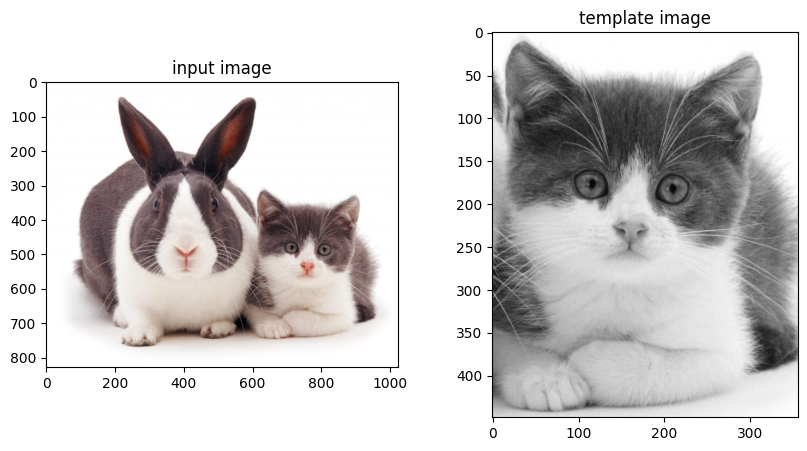

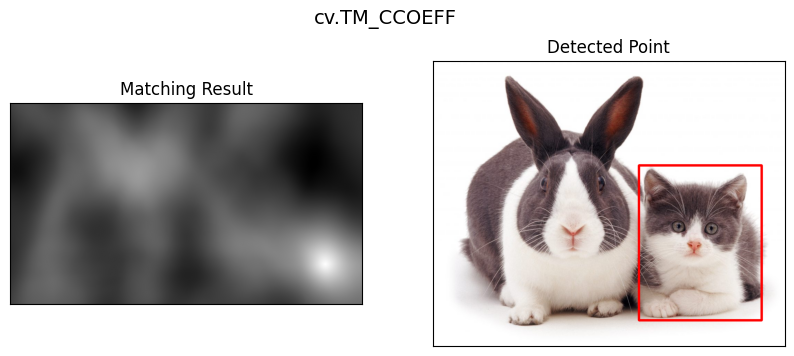

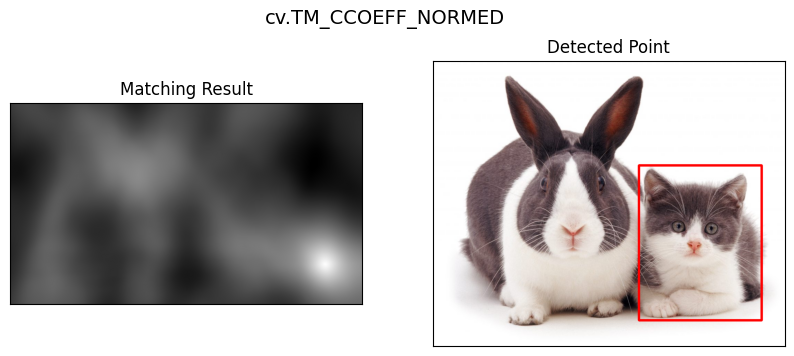

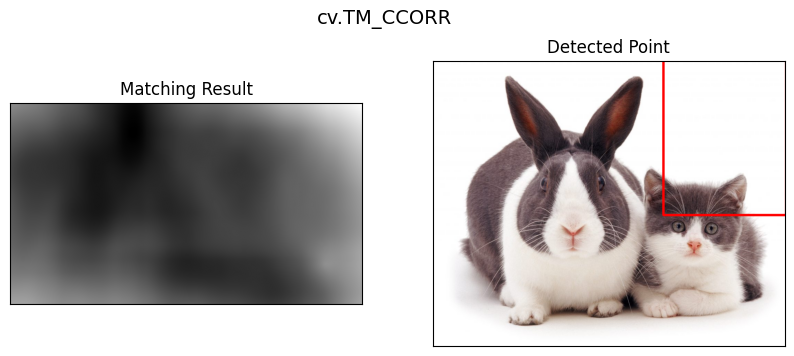

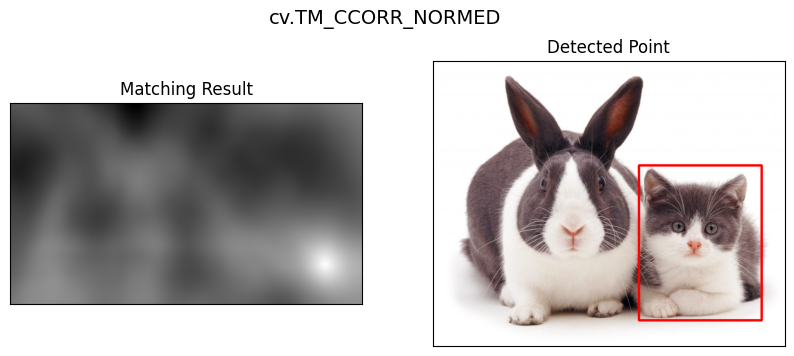

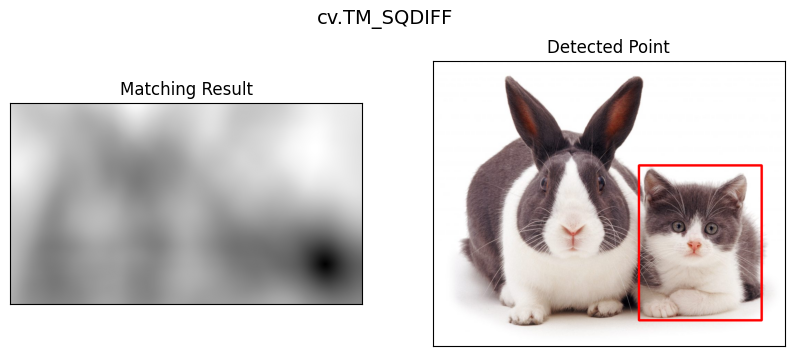

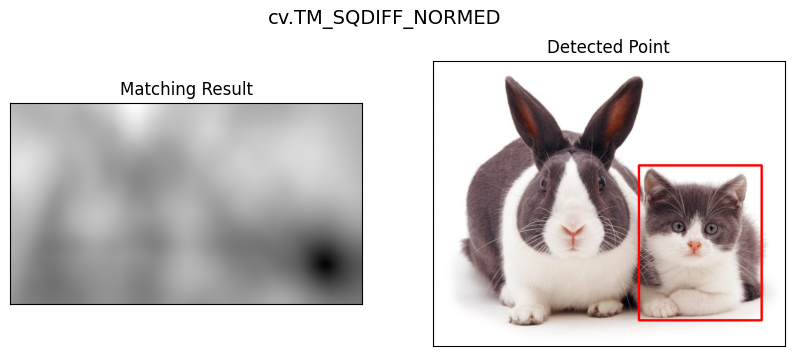

In [77]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

# Membaca citra input dan citra template
img_bgr = cv.imread(folder_path + 'cats_and_bunnies.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

template = cv.imread(folder_path + 'cat2_templatejpg.jpg', 0)
w, h = template.shape[::-1]

# Menampilkan Input Image dan Template Image berdampingan
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_rgb)
plt.title('input image')
plt.subplot(122), plt.imshow(template, cmap='gray')
plt.title('template image')
plt.show()

# Daftar 6 metode Template Matching di OpenCV
methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
           'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

# 3. Melakukan perulangan untuk menerapkan keenam metode
for meth in methods:
    img_display = img_rgb.copy()
    method = eval(meth)

    # Menerapkan template matching
    res = cv.matchTemplate(img_gray, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    # Jika metodenya TM_SQDIFF atau TM_SQDIFF_NORMED, ambil nilai minimum
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)

    # Menggambar kotak pembatas (bounding box) warna merah
    cv.rectangle(img_display, top_left, bottom_right, (255, 0, 0), 5)

    # Menampilkan hasil Matching Result dan Detected Point
    plt.figure(figsize=(10, 4))

    plt.subplot(121),
    plt.imshow(res, cmap='gray'),
    plt.title('Matching Result'),
    plt.xticks([]),
    plt.yticks([]),

    plt.subplot(122),
    plt.imshow(img_display),
    plt.title('Detected Point'),
    plt.xticks([]),
    plt.yticks([]),
    plt.suptitle(meth, fontsize=14)
    plt.show()

### **3. Implementasi Template Matching Tanpa Library OpenCV untuk Multiple Object**

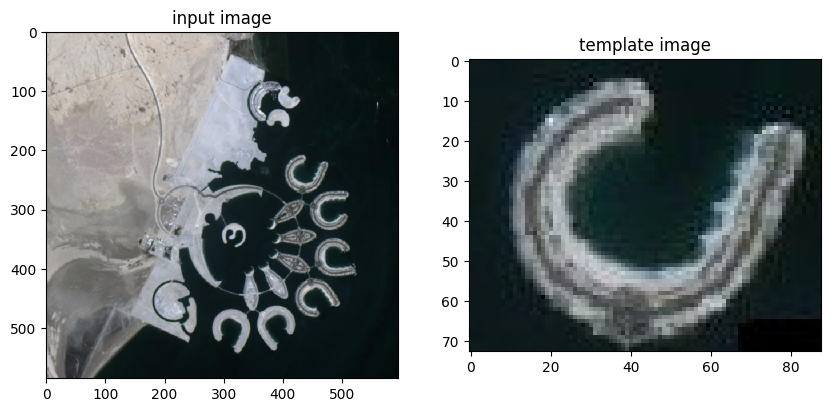

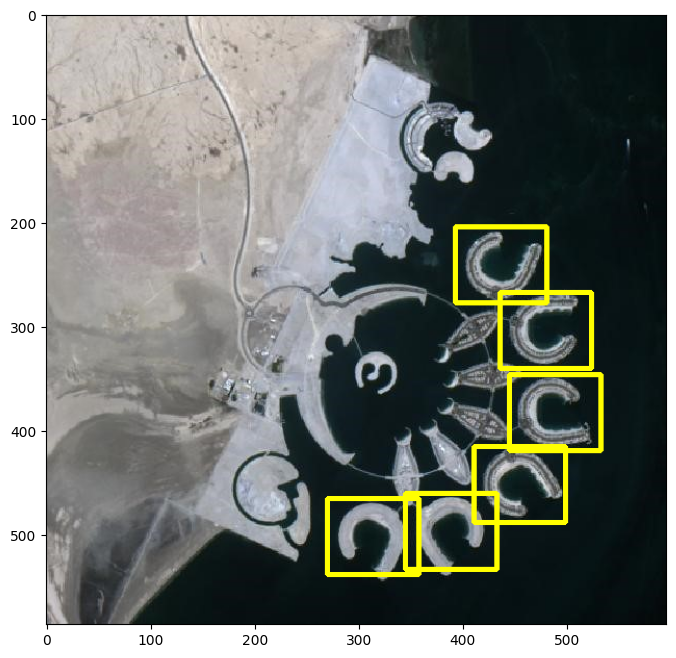

In [78]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

# Membaca dan menyiapkan citra input serta citra template
img_rgb = cv.cvtColor(cv.imread(folder_path + 'bahrain.jpg'), cv.COLOR_BGR2RGB)
temp_rgb = cv.cvtColor(cv.imread(folder_path + 'bahrain-template.jpg'), cv.COLOR_BGR2RGB)

img_gray = cv.cvtColor(img_rgb, cv.COLOR_RGB2GRAY).astype(float)
temp_gray = cv.cvtColor(temp_rgb, cv.COLOR_RGB2GRAY).astype(float)

# Menampilkan citra input dan citra template
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_rgb), plt.title('input image')
plt.subplot(122), plt.imshow(temp_rgb), plt.title('template image')
plt.show()

# Perhitungan manual Template Matching (Normalized Cross-Correlation)
H, W = img_gray.shape
h, w = temp_gray.shape
R = np.zeros((H - h + 1, W - w + 1))

temp_diff = temp_gray - np.mean(temp_gray)
temp_norm = np.linalg.norm(temp_diff)

for y in range(H - h + 1):
    for x in range(W - w + 1):
        patch_diff = img_gray[y:y+h, x:x+w] - np.mean(img_gray[y:y+h, x:x+w])
        patch_norm = np.linalg.norm(patch_diff)

        if patch_norm > 0:
            R[y, x] = np.sum(temp_diff * patch_diff) / (temp_norm * patch_norm)

# Menyeleksi 6 koordinat terbaik menggunakan Non-Maximum Suppression (NMS)
R[:180, :] = -1  # Abaikan area daratan atas
R[:, :250] = -1  # Abaikan area daratan kiri

img_result = img_rgb.copy()
nms_h, nms_w = int(h * 0.65), int(w * 0.65)

for _ in range(6):
    y_max, x_max = np.unravel_index(np.argmax(R), R.shape)

    # Menggambar kotak pembatas warna kuning pada titik terpilih
    cv.rectangle(img_result, (x_max, y_max), (x_max + w, y_max + h), (255, 255, 0), 3)

    # Menghapus nilai di sekitar titik terpilih agar objek yang sama tidak terdeteksi ulang
    R[max(0, y_max - nms_h):min(R.shape[0], y_max + nms_h),
      max(0, x_max - nms_w):min(R.shape[1], x_max + nms_w)] = -1

# Menampilkan hasil akhir deteksi objek
plt.figure(figsize=(8, 8))
plt.imshow(img_result)
plt.show()

### **4. Implementasi Metode Edge Detection (Sobel, Canny, dan Laplacian)**

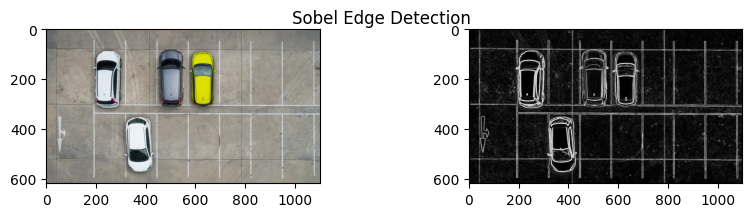

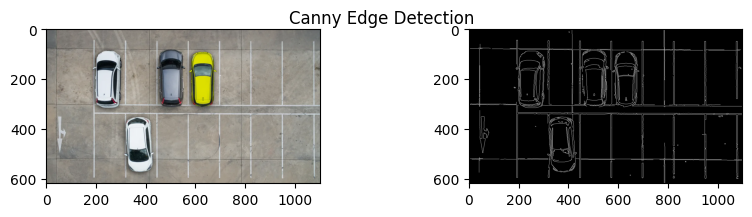

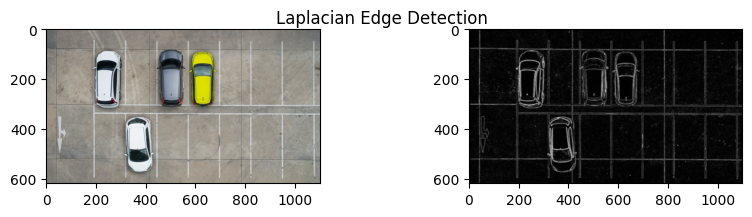

In [79]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

img_bgr = cv.imread(folder_path + 'car-park.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

img_blur = cv.GaussianBlur(img_gray, (3, 3), 0)

# Sobel Edge Detection
sobel_x = cv.Sobel(img_blur, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(img_blur, cv.CV_64F, 0, 1, ksize=3)
sobel_combined = cv.magnitude(sobel_x, sobel_y)
sobel_edges = cv.convertScaleAbs(sobel_combined)

plt.figure(figsize=(10, 2))
plt.suptitle('Sobel Edge Detection')
plt.subplot(121), plt.imshow(img_rgb)
plt.subplot(122), plt.imshow(sobel_edges, cmap='gray')
plt.show()

# Canny Edge Detection
canny_edges = cv.Canny(img_blur, 100, 200)

plt.figure(figsize=(10, 2))
plt.suptitle('Canny Edge Detection')
plt.subplot(121), plt.imshow(img_rgb)
plt.subplot(122), plt.imshow(canny_edges, cmap='gray')
plt.show()

# Laplacian Edge Detection
laplacian = cv.Laplacian(img_blur, cv.CV_64F, ksize=3)
laplacian_edges = cv.convertScaleAbs(laplacian)

plt.figure(figsize=(10, 2))
plt.suptitle('Laplacian Edge Detection')
plt.subplot(121), plt.imshow(img_rgb)
plt.subplot(122), plt.imshow(laplacian_edges, cmap='gray')
plt.show()

### **5. Implementasi Metode Corner Detection (Harris dan Shi-Tomasi)**

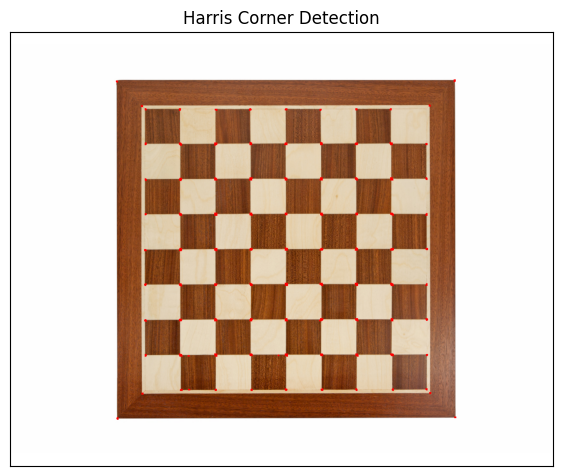

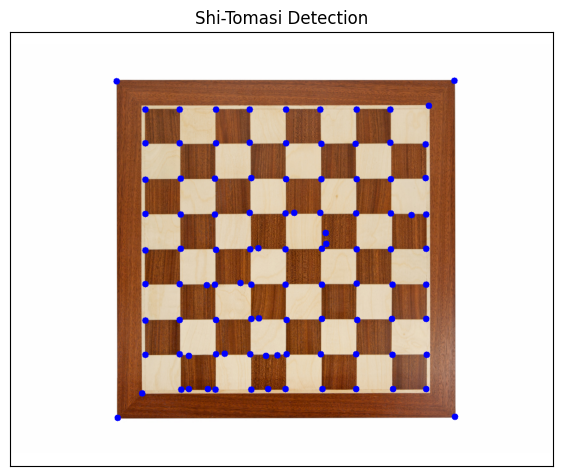

In [80]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

img_bgr = cv.imread(folder_path + 'chess-board.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Harris Corner Detection
img_harris = img_rgb.copy()
gray_float = np.float32(img_gray)

dst = cv.cornerHarris(gray_float, 2, 3, 0.04)

# Dilasi hasil corner agar titik sudut merah terlihat lebih jelas
dst = cv.dilate(dst, None)

# Menandai sudut yang melebihi threshold
img_harris[dst > 0.01 * dst.max()] = [255, 0, 0]

plt.figure(figsize=(7, 7))
plt.title('Harris Corner Detection')
plt.imshow(img_harris)
plt.xticks([]), plt.yticks([])
plt.show()



# Shi-Tomasi Detection
img_shitomasi = img_rgb.copy()

corners = cv.goodFeaturesToTrack(img_gray, 100, 0.01, 10)
corners = np.intp(corners)

# Menggambar titik lingkaran biru pada setiap sudut yang ditemukan
for i in corners:
    x, y = i.ravel()
    cv.circle(img_shitomasi, (x, y), 6, (0, 0, 255), -1)

plt.figure(figsize=(7, 7))
plt.title('Shi-Tomasi Detection')
plt.imshow(img_shitomasi)
plt.xticks([]), plt.yticks([])
plt.show()

### **6. Implementasi Grid Detection dengan Metode Hough Transform**

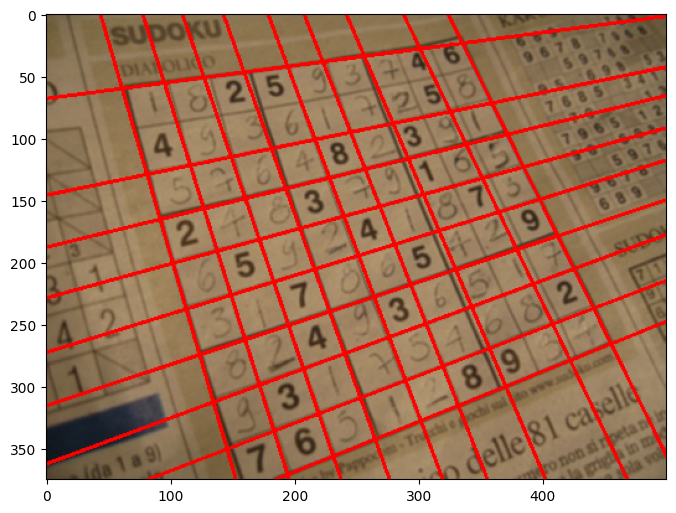

In [81]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

img_bgr = cv.imread(folder_path + 'sudoku.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

img_blur = cv.GaussianBlur(img_gray, (5, 5), 0)

# Canny Edge Detection
edges = cv.Canny(img_blur, 50, 150, apertureSize=3)

# HoughLines
lines = cv.HoughLines(edges, 1, np.pi / 180, 110)

# Filter garis duplikat
def filter_lines(lines, rho_thresh=20, theta_thresh=np.deg2rad(8)):
    if lines is None:
        return []
    lines = [l[0] for l in lines]
    groups = []
    for rho, theta in lines:
        placed = False
        for g in groups:
            g_rho, g_theta = np.mean(g, axis=0)
            if abs(rho - g_rho) < rho_thresh and abs(theta - g_theta) < theta_thresh:
                g.append((rho, theta))
                placed = True
                break
        if not placed:
            groups.append([(rho, theta)])
    return [tuple(np.mean(g, axis=0)) for g in groups]

filtered = filter_lines(lines)

# Menggambar garis merah hasil Hough Transform pada citra
img_hough = img_rgb.copy()
for rho, theta in filtered:
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv.line(img_hough, (x1, y1), (x2, y2), (255, 0, 0), 2)

# Menampilkan hasil gambar
plt.figure(figsize=(8, 8))
plt.imshow(img_hough)
plt.show()

### **7. Implementasi Contour Detection**

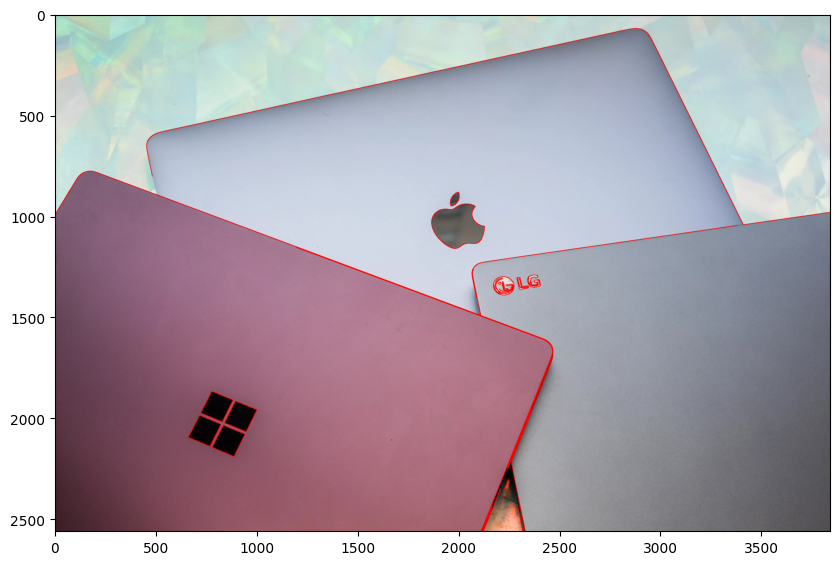

In [82]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

img_bgr = cv.imread(folder_path + 'laptop.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Mengubah citra menjadi citra biner menggunakan Canny Edge Detection
img_blur = cv.GaussianBlur(img_gray, (5, 5), 0)
edges = cv.Canny(img_blur, 50, 150)

# Menemukan kontur menggunakan cv.findContours()
contours, hierarchy = cv.findContours(edges, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

# Menggambarkan kontur
img_contour = img_rgb.copy()
cv.drawContours(img_contour, contours, -1, (255, 0, 0), 2)

# 5. Menampilkan hasil akhir Contour Detection
plt.figure(figsize=(10, 10))
plt.imshow(img_contour)
plt.show()

# **D2. Praktikum Feature Matching dan Face Detection**

### **8. Face Detection Menggunakan Haar Cascades**

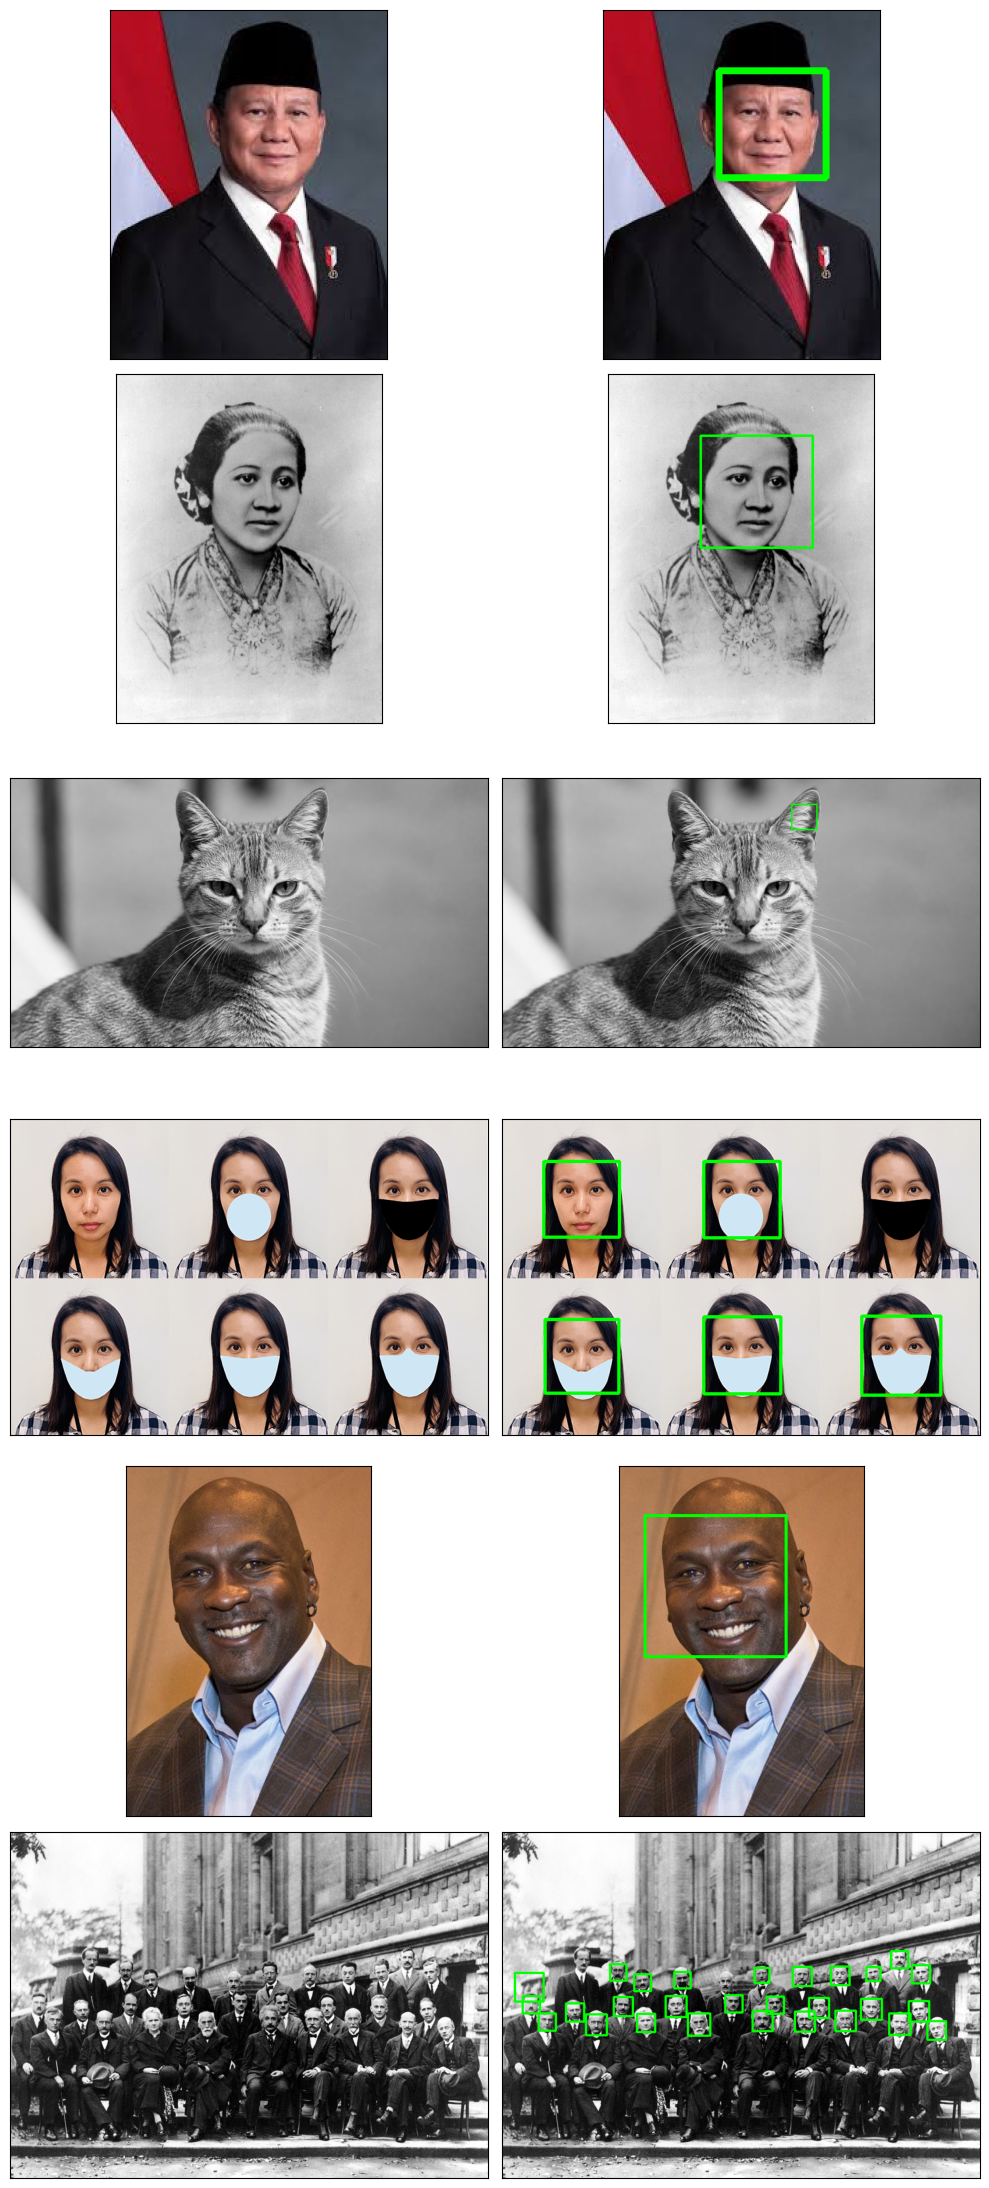

In [83]:
folder_path_haarcascades = '/content/drive/MyDrive/Semester 5/PCVK/images/haarcascades/'
folder_path_facedet = '/content/drive/MyDrive/Semester 5/PCVK/images/facedet/'

# Memuat model pretrained Haar Cascade untuk wajah
cascade_wajah = cv.CascadeClassifier(folder_path_haarcascades + 'haarcascade_frontalface_alt.xml')

daftar_gambar = [
    'prabowo.jpg',
    'kartini.jpg',
    'cat.png',
    'mask.png',
    'mjordan.jpg',
    'solvayconf.jpg'
]

plt.figure(figsize=(10, 22))

for i, nama_file in enumerate(daftar_gambar):
    img_path = os.path.join(folder_path_facedet, nama_file)
    img_bgr = cv.imread(img_path)

    img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

    # Mendeteksi koordinat wilayah wajah
    roi_wajah = cascade_wajah.detectMultiScale(img_gray)

    # Menggambar kotak hijau di sekeliling wajah yang terdeteksi
    img_result = img_bgr.copy()
    for (x, y, w, h) in roi_wajah:
        cv.rectangle(img_result, (x, y), (x + w, y + h), (0, 255, 0), 3)

    # Konversi BGR ke RGB untuk ditampilkan di matplotlib
    img_asli_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
    img_result_rgb = cv.cvtColor(img_result, cv.COLOR_BGR2RGB)

    # Citra Asli
    plt.subplot(len(daftar_gambar), 2, 2 * i + 1)
    plt.imshow(img_asli_rgb)
    plt.xticks([]), plt.yticks([])

    # Hasil Face Detection
    plt.subplot(len(daftar_gambar), 2, 2 * i + 2)
    plt.imshow(img_result_rgb)
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

### **9. Face Detection pada Wajah Kucing**

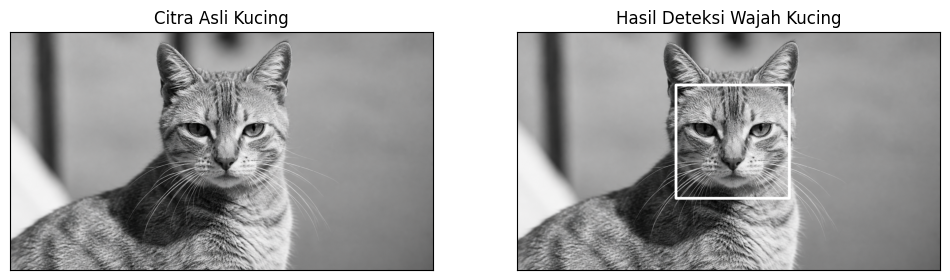

In [84]:
folder_path_haarcascades = '/content/drive/MyDrive/Semester 5/PCVK/images/haarcascades/'
folder_path_facedet = '/content/drive/MyDrive/Semester 5/PCVK/images/facedet/'


# Memuat model pretrained Haar Cascade khusus wajah kucing
cascade_kucing = cv.CascadeClassifier(folder_path_haarcascades + '/haarcascade_frontalcatface.xml')

img_bgr = cv.imread(folder_path_facedet + 'cat.png')
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# 3. Mendeteksi koordinat wilayah wajah kucing
roi_kucing = cascade_kucing.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=3)

# 4. Menggambar kotak berwarna putih di sekeliling wajah kucing yang terdeteksi
img_result = img_bgr.copy()
for (x, y, w, h) in roi_kucing:
    cv.rectangle(img_result, (x, y), (x + w, y + h), (255, 255, 255), 10)


img_asli_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_result_rgb = cv.cvtColor(img_result, cv.COLOR_BGR2RGB)


plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_asli_rgb)
plt.title('Citra Asli Kucing')
plt.xticks([]), plt.yticks([])

plt.subplot(1, 2, 2)
plt.imshow(img_result_rgb)
plt.title('Hasil Deteksi Wajah Kucing')
plt.xticks([]), plt.yticks([])

plt.show()

### **10. Eyes Detection pada Wajah Pak Prabowo**

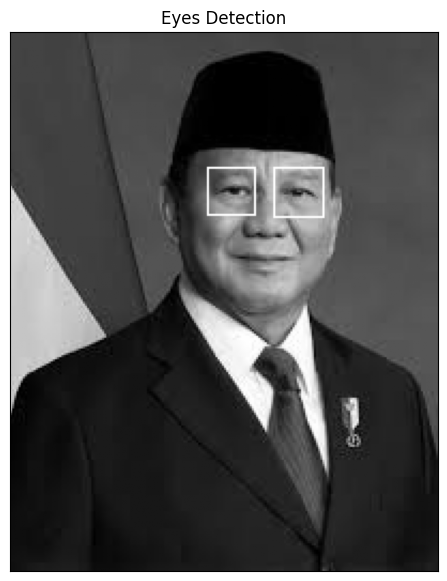

In [85]:
folder_path_haarcascades = '/content/drive/MyDrive/Semester 5/PCVK/images/haarcascades/'
folder_path_facedet = '/content/drive/MyDrive/Semester 5/PCVK/images/facedet/'

# Memuat model pretrained Haar Cascade untuk wajah dan mata
cascade_wajah = cv.CascadeClassifier(folder_path_haarcascades + '/haarcascade_frontalface_alt.xml')
cascade_mata = cv.CascadeClassifier(folder_path_haarcascades + '/haarcascade_eye.xml')

img_bgr = cv.imread(folder_path_facedet + 'prabowo.jpg')
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Mendeteksi wilayah wajah
roi_wajah = cascade_wajah.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=5)

img_result = img_bgr.copy()

# 4. Mendeteksi mata di dalam area wajah
for (x, y, w, h) in roi_wajah:
    roi_gray = img_gray[y:y+h, x:x+w]
    roi_color = img_result[y:y+h, x:x+w]

    mata = cascade_mata.detectMultiScale(roi_gray, scaleFactor=1.1, minNeighbors=1)
    for (ex, ey, ew, eh) in mata:
        cv.rectangle(roi_color, (ex, ey), (ex + ew, ey + eh), (255, 255, 255), 1)


img_result_gray = cv.cvtColor(img_result, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(7, 7))
plt.imshow(img_result_gray, cmap='gray')
plt.title('Eyes Detection')
plt.xticks([]), plt.yticks([])
plt.show()

### **11. Deteksi Senyuman pada Gambar People**

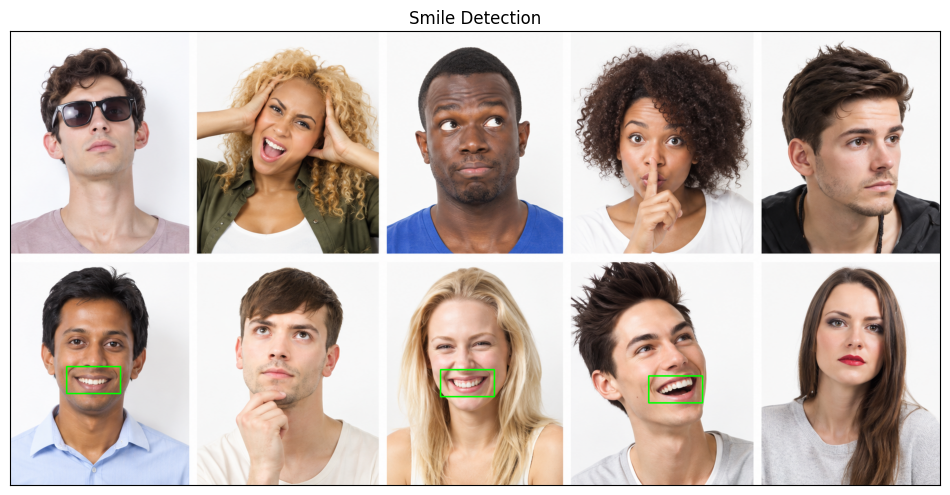

In [86]:
folder_path_haarcascades = '/content/drive/MyDrive/Semester 5/PCVK/images/haarcascades/'
folder_path_facedet = '/content/drive/MyDrive/Semester 5/PCVK/images/facedet/'

# Memuat model pretrained Haar Cascade untuk wajah dan senyuman
cascade_wajah = cv.CascadeClassifier(folder_path_haarcascades + '/haarcascade_frontalface_alt.xml')
cascade_senyum = cv.CascadeClassifier(folder_path_haarcascades + '/haarcascade_smile.xml')

img_bgr = cv.imread(folder_path_facedet + 'people.png')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Mendeteksi wajah terlebih dahulu agar pencarian senyuman fokus di area wajah
wajah = cascade_wajah.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=3)

img_result = img_rgb.copy()

for (x, y, w, h) in wajah:
    # Mengambil ROI bagian bawah wajah tempat mulut berada
    roi_gray = img_gray[y:y+h, x:x+w]
    roi_color = img_result[y:y+h, x:x+w]

    # Mendeteksi senyuman di dalam area wajah
    senyum = cascade_senyum.detectMultiScale(roi_gray, scaleFactor=1.7, minNeighbors=5)

    for (sx, sy, sw, sh) in senyum:
        cv.rectangle(roi_color, (sx, sy), (sx + sw, sy + sh), (0, 255, 0), 2)

plt.figure(figsize=(12, 8))
plt.imshow(img_result)
plt.title('Smile Detection')
plt.xticks([]), plt.yticks([])
plt.show()

### **12. Face Tracking**

In [87]:
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import cv2
import numpy as np
import PIL
import io
import html
import time

#### Helper Functions

In [88]:
# function to convert the JavaScript object into an OpenCV image
def js_to_image(js_reply):
  """
  Params:
          js_reply: JavaScript object containing image from webcam
  Returns:
          img: OpenCV BGR image
  """
  # decode base64 image
  image_bytes = b64decode(js_reply.split(',')[1])
  # convert bytes to numpy array
  jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
  # decode numpy array into OpenCV BGR image
  img = cv2.imdecode(jpg_as_np, flags=1)

  return img

# function to convert OpenCV Rectangle bounding box image into base64 byte string to be overlayed on video stream
def bbox_to_bytes(bbox_array):
  """
  Params:
          bbox_array: Numpy array (pixels) containing rectangle to overlay on video stream.
  Returns:
        bytes: Base64 image byte string
  """
  # convert array into PIL image
  bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')
  iobuf = io.BytesIO()
  # format bbox into png for return
  bbox_PIL.save(iobuf, format='png')
  # format return string
  bbox_bytes = 'data:image/png;base64,{}'.format((str(b64encode(iobuf.getvalue()), 'utf-8')))

  return bbox_bytes

#### Haar Cascade Classifier

In [90]:
folder_path_haarcascades = '/content/drive/MyDrive/Semester 5/PCVK/images/haarcascades/'

# initialize the Haar Cascade face detection model
face_cascade = cv2.CascadeClassifier(folder_path_haarcascades + '/haarcascade_frontalface_default.xml')

#### Webcam Images

In [91]:
def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)

  # get photo data
  data = eval_js('takePhoto({})'.format(quality))
  # get OpenCV format image
  img = js_to_image(data)
  # grayscale img
  gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
  print(gray.shape)
  # get face bounding box coordinates using Haar Cascade
  faces = face_cascade.detectMultiScale(gray)
  # draw face bounding box on image
  for (x,y,w,h) in faces:
      img = cv2.rectangle(img,(x,y),(x+w,y+h),(255,0,0),2)
  # save image
  cv2.imwrite(filename, img)

  return filename

<IPython.core.display.Javascript object>

(480, 640)
Saved to photo.jpg


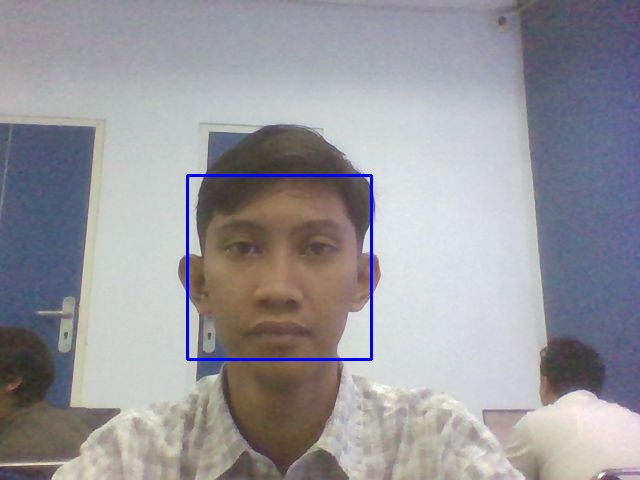

In [101]:
try:
  filename = take_photo('photo.jpg')
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  display(Image(filename))
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or if they do not
  # grant the page permission to access it.
  print(str(err))

#### Webcam Videos

In [95]:
# JavaScript to properly create our live video stream using our webcam as input
def video_stream():
  js = Javascript('''
    var video;
    var div = null;
    var stream;
    var captureCanvas;
    var imgElement;
    var labelElement;

    var pendingResolve = null;
    var shutdown = false;

    function removeDom() {
       stream.getVideoTracks()[0].stop();
       video.remove();
       div.remove();
       video = null;
       div = null;
       stream = null;
       imgElement = null;
       captureCanvas = null;
       labelElement = null;
    }

    function onAnimationFrame() {
      if (!shutdown) {
        window.requestAnimationFrame(onAnimationFrame);
      }
      if (pendingResolve) {
        var result = "";
        if (!shutdown) {
          captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
          result = captureCanvas.toDataURL('image/jpeg', 0.8)
        }
        var lp = pendingResolve;
        pendingResolve = null;
        lp(result);
      }
    }

    async function createDom() {
      if (div !== null) {
        return stream;
      }

      div = document.createElement('div');
      div.style.border = '2px solid black';
      div.style.padding = '3px';
      div.style.width = '100%';
      div.style.maxWidth = '600px';
      document.body.appendChild(div);

      const modelOut = document.createElement('div');
      modelOut.innerHTML = "<span>Status:</span>";
      labelElement = document.createElement('span');
      labelElement.innerText = 'No data';
      labelElement.style.fontWeight = 'bold';
      modelOut.appendChild(labelElement);
      div.appendChild(modelOut);

      video = document.createElement('video');
      video.style.display = 'block';
      video.width = div.clientWidth - 6;
      video.setAttribute('playsinline', '');
      video.onclick = () => { shutdown = true; };
      stream = await navigator.mediaDevices.getUserMedia(
          {video: { facingMode: "environment"}});
      div.appendChild(video);

      imgElement = document.createElement('img');
      imgElement.style.position = 'absolute';
      imgElement.style.zIndex = 1;
      imgElement.onclick = () => { shutdown = true; };
      div.appendChild(imgElement);

      const instruction = document.createElement('div');
      instruction.innerHTML =
          '<span style="color: red; font-weight: bold;">' +
          'When finished, click here or on the video to stop this demo</span>';
      div.appendChild(instruction);
      instruction.onclick = () => { shutdown = true; };

      video.srcObject = stream;
      await video.play();

      captureCanvas = document.createElement('canvas');
      captureCanvas.width = 640; //video.videoWidth;
      captureCanvas.height = 480; //video.videoHeight;
      window.requestAnimationFrame(onAnimationFrame);

      return stream;
    }
    async function stream_frame(label, imgData) {
      if (shutdown) {
        removeDom();
        shutdown = false;
        return '';
      }

      var preCreate = Date.now();
      stream = await createDom();

      var preShow = Date.now();
      if (label != "") {
        labelElement.innerHTML = label;
      }

      if (imgData != "") {
        var videoRect = video.getClientRects()[0];
        imgElement.style.top = videoRect.top + "px";
        imgElement.style.left = videoRect.left + "px";
        imgElement.style.width = videoRect.width + "px";
        imgElement.style.height = videoRect.height + "px";
        imgElement.src = imgData;
      }

      var preCapture = Date.now();
      var result = await new Promise(function(resolve, reject) {
        pendingResolve = resolve;
      });
      shutdown = false;

      return {'create': preShow - preCreate,
              'show': preCapture - preShow,
              'capture': Date.now() - preCapture,
              'img': result};
    }
    ''')

  display(js)

def video_frame(label, bbox):
  data = eval_js('stream_frame("{}", "{}")'.format(label, bbox))
  return data

In [102]:
# start streaming video from webcam
video_stream()
# label for video
label_html = 'Capturing...'
# initialze bounding box to empty
bbox = ''
count = 0
while True:
    js_reply = video_frame(label_html, bbox)
    if not js_reply:
        break

    # convert JS response to OpenCV Image
    img = js_to_image(js_reply["img"])

    # create transparent overlay for bounding box
    bbox_array = np.zeros([480,640,4], dtype=np.uint8)

    # grayscale image for face detection
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # get face region coordinates
    faces = face_cascade.detectMultiScale(gray)
    # get face bounding box for overlay
    for (x,y,w,h) in faces:
      bbox_array = cv2.rectangle(bbox_array,(x,y),(x+w,y+h),(255,0,0),2)

    bbox_array[:,:,3] = (bbox_array.max(axis = 2) > 0 ).astype(int) * 255
    # convert overlay of bbox into bytes
    bbox_bytes = bbox_to_bytes(bbox_array)
    # update bbox so next frame gets new overlay
    bbox = bbox_bytes

<IPython.core.display.Javascript object>

/tmp/ipykernel_33613/480462610.py:27: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')


### **13. Blurring pada Bagian Wajah**

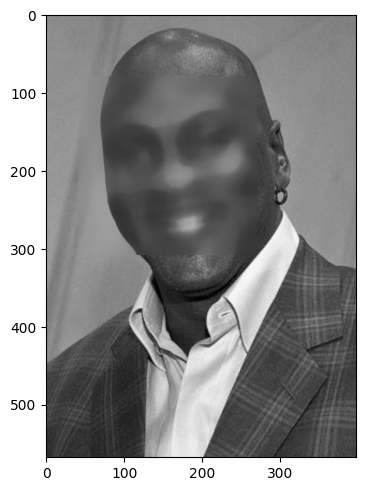

In [109]:
folder_path_haarcascades = '/content/drive/MyDrive/Semester 5/PCVK/images/haarcascades/'
folder_path_facedet = '/content/drive/MyDrive/Semester 5/PCVK/images/facedet/'

# Memuat model pretrained Haar Cascade untuk wajah
cascade_wajah = cv.CascadeClassifier(folder_path_haarcascades + 'haarcascade_frontalface_alt.xml')

img_gray = cv.imread(folder_path_facedet + 'mjordan.jpg', 0)

# Mendeteksi koordinat wilayah wajah
roi_wajah = cascade_wajah.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=5)

# Melakukan blurring
img_blur = img_gray.copy()
for (x, y, w, h) in roi_wajah:
    potongan_wajah = img_blur[y:y+h, x:x+w]

    # Menerapkan medianBlur
    wajah_kabur = cv.medianBlur(potongan_wajah, 25)

    img_blur[y:y+h, x:x+w] = wajah_kabur

plt.figure(figsize=(4, 7))
plt.imshow(img_blur, cmap='gray')
plt.show()

### **14. Mengolah Gambar KTM (Face Cropping & Feature Matching)**

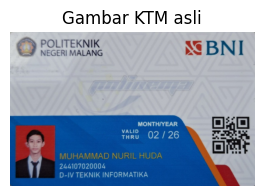

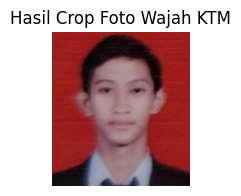

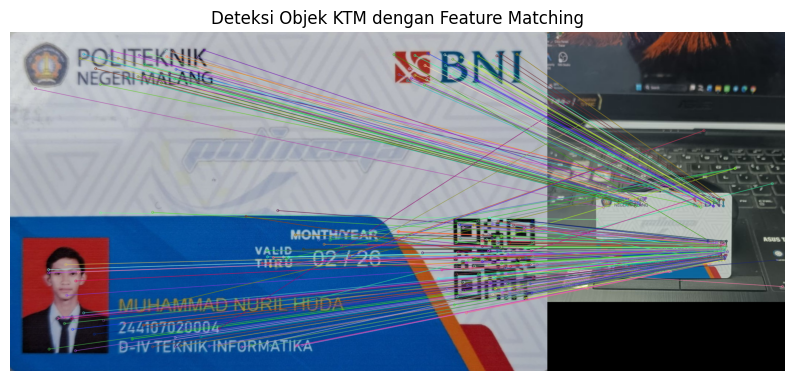

In [119]:
folder_path_haarcascades = '/content/drive/MyDrive/Semester 5/PCVK/images/haarcascades/'

# ==========================================
# Menampilkan Gambar KTM Utuh
# ==========================================
ktm_bgr = cv.imread('/content/drive/MyDrive/Semester 5/PCVK/images/244107020004/KTM1d.jpg')
ktm_rgb = cv.cvtColor(ktm_bgr, cv.COLOR_BGR2RGB)
ktm_gray = cv.cvtColor(ktm_bgr, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(4, 2))
plt.imshow(ktm_rgb)
plt.title('Gambar KTM asli')
plt.axis('off')
plt.show()

# ==========================================
# Face Cropping
# ==========================================
cascade_wajah = cv2.CascadeClassifier(folder_path_haarcascades + 'haarcascade_frontalface_alt.xml')
roi_wajah = cascade_wajah.detectMultiScale(ktm_gray, scaleFactor=1.1, minNeighbors=4)

# Mengambil koordinat wajah pertama yang terdeteksi
x, y, w, h = roi_wajah[0]

# Memberikan margin (padding) agar area pas foto KTM terpotong rapi
pad_x = int(w * 0.35)
pad_y_top = int(h * 0.35)
pad_y_bottom = int(h * 0.55)

y1 = max(0, y - pad_y_top)
y2 = min(ktm_rgb.shape[0], y + h + pad_y_bottom)
x1 = max(0, x - pad_x)
x2 = min(ktm_rgb.shape[1], x + w + pad_x)

foto_ktm = ktm_rgb[y1:y2, x1:x2]

plt.figure(figsize=(2, 2))
plt.imshow(foto_ktm)
plt.title('Hasil Crop Foto Wajah KTM')
plt.axis('off')
plt.show()

# ==========================================
# Feature Matching
# ==========================================
ktm_scene_bgr = cv2.imread('/content/drive/MyDrive/Semester 5/PCVK/images/244107020004/KTM_barang.jpeg')
ktm_scene = cv2.cvtColor(ktm_scene_bgr, cv2.COLOR_BGR2RGB)

# Inisialisasi SIFT
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(ktm_rgb, None)
kp2, des2 = sift.detectAndCompute(ktm_scene, None)

# Brute-Force Matcher dengan kNN (k=2)
bf = cv2.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

# Ratio Test untuk menyaring kecocokan terbaik
good = []
for match1, match2 in matches:
    if match1.distance < 0.75 * match2.distance:
        good.append([match1])

# Menggambar garis penghubung kecocokan fitur SIFT
sift_matches = cv2.drawMatchesKnn(ktm_rgb, kp1, ktm_scene, kp2, good, None, flags=2)

plt.figure(figsize=(10, 6))
plt.imshow(sift_matches)
plt.title('Deteksi Objek KTM dengan Feature Matching')
plt.axis('off')
plt.show()